In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import math

In [2]:
df = pd.read_csv(
    "train_FD001.txt",
    sep=r"\s+",
    header=None
)

print(df)

        0    1       2       3      4       5       6        7        8   \
0        1    1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60   
1        1    2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14   
2        1    3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20   
3        1    4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87   
4        1    5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22   
...    ...  ...     ...     ...    ...     ...     ...      ...      ...   
20626  100  196 -0.0004 -0.0003  100.0  518.67  643.49  1597.98  1428.63   
20627  100  197 -0.0016 -0.0005  100.0  518.67  643.54  1604.50  1433.58   
20628  100  198  0.0004  0.0000  100.0  518.67  643.42  1602.46  1428.18   
20629  100  199 -0.0011  0.0003  100.0  518.67  643.23  1605.26  1426.53   
20630  100  200 -0.0032 -0.0005  100.0  518.67  643.85  1600.38  1432.14   

          9   ...      16       17       18      19    20   21    22     23  \
0      1

In [3]:
columns = (
    ["unit", "cycle", "setting1", "setting2", "setting3"]
    + [f"sensor{i}" for i in range(1, 22)]
)

df.columns = columns

print(df)

       unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0         1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1         1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2         1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3         1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4         1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   
...     ...    ...       ...       ...       ...      ...      ...      ...   
20626   100    196   -0.0004   -0.0003     100.0   518.67   643.49  1597.98   
20627   100    197   -0.0016   -0.0005     100.0   518.67   643.54  1604.50   
20628   100    198    0.0004    0.0000     100.0   518.67   643.42  1602.46   
20629   100    199   -0.0011    0.0003     100.0   518.67   643.23  1605.26   
20630   100    200   -0.0032   -0.0005     100.0   518.67   643.85  1600.38   

       sensor4  sensor5  ...  sensor12  sensor13  s

In [4]:
max_cycle = df.groupby("unit")["cycle"].max()
max_cycle = df["unit"].map(max_cycle)
df['RUL'] = max_cycle-df['cycle']
df

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,1


In [5]:
from sklearn.model_selection import train_test_split

units = df["unit"].unique()

train_units, val_units = train_test_split(
    units,
    test_size=0.2,
    random_state=42
)

train_df = df[df["unit"].isin(train_units)].copy()
val_df = df[df["unit"].isin(val_units)].copy()

In [6]:
from sklearn.preprocessing import StandardScaler

features = [f"setting{i}" for i in range(1, 4)] + \
           [f"sensor{i}" for i in range(1, 22)]

scaler = StandardScaler()

train_df[features] = scaler.fit_transform(train_df[features])
val_df[features] = scaler.transform(val_df[features])

In [7]:
def create_sequences(df, features, window_size=20):

    X = []
    y = []

    for unit in df["unit"].unique():

        engine = df[df["unit"] == unit]

        values = engine[features].values
        rul = engine["RUL"].values

        for i in range(len(engine) - window_size + 1):

            X.append(values[i:i + window_size])
            y.append(rul[i + window_size - 1])

    return np.array(X), np.array(y)

In [8]:
X_train, y_train = create_sequences(
    train_df,
    features,
    window_size=20
)

X_val, y_val = create_sequences(
    val_df,
    features,
    window_size=20
)

In [9]:
from sklearn.model_selection import train_test_split

units = df["unit"].unique()

train_units, val_units = train_test_split(
    units,
    test_size=0.2,
    random_state=42
)

train_df = df[df["unit"].isin(train_units)].copy()
val_df = df[df["unit"].isin(val_units)].copy()

In [10]:
print(X_train.shape)
print(y_train.shape)

print(X_val.shape)
print(y_val.shape)

(15041, 20, 24)
(15041,)
(3690, 20, 24)
(3690,)


In [11]:
import torch

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

In [12]:
from torch.utils.data import TensorDataset

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

In [13]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

In [14]:
for X_batch, y_batch in train_loader:
    print(X_batch.shape)
    print(y_batch.shape)
    break

torch.Size([128, 20, 24])
torch.Size([128])


In [15]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        out, (h_n, c_n) = self.lstm(x)

        out = out[:, -1, :]

        out = self.fc(out)

        return out.squeeze(-1)

In [16]:
model = LSTMModel(
    input_size=24,
    hidden_size=64,
    num_layers=1,
)

In [17]:
criterion = nn.MSELoss()

In [18]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.002
)

In [19]:
X_batch, y_batch = next(iter(train_loader))

pred = model(X_batch)

print(X_batch.shape)
print(y_batch.shape)
print(pred.shape)

torch.Size([128, 20, 24])
torch.Size([128])
torch.Size([128])


In [20]:
loss = criterion(pred, y_batch)

print(loss)

tensor(15189.5459, grad_fn=<MseLossBackward0>)


In [21]:
num_epochs = 40
patience = 5

best_val_loss = float("inf")
patience_counter = 0

for epoch in range(num_epochs):

    # =====================
    # TRAIN
    # =====================
    model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)


    # =====================
    # VALIDATION
    # =====================
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)


    print(
        f"Epoch {epoch+1:02d}/{num_epochs} "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )


    # =====================
    # EARLY STOPPING
    # =====================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        # Save best model
        torch.save(model.state_dict(), "best_lstm_model.pth")

    else:

        patience_counter += 1

        if patience_counter >= patience:

            print("Early stopping!")
            break
        
model.load_state_dict(
    torch.load("best_lstm_model.pth")
)

Epoch 01/40 | Train Loss: 12091.4482 | Val Loss: 9436.5798
Epoch 02/40 | Train Loss: 9326.0034 | Val Loss: 7322.3970
Epoch 03/40 | Train Loss: 7440.2821 | Val Loss: 5774.6822
Epoch 04/40 | Train Loss: 6013.8377 | Val Loss: 4603.4447
Epoch 05/40 | Train Loss: 4920.6620 | Val Loss: 3702.7020
Epoch 06/40 | Train Loss: 4084.6626 | Val Loss: 3024.1483
Epoch 07/40 | Train Loss: 3432.2089 | Val Loss: 2504.0849
Epoch 08/40 | Train Loss: 2938.2967 | Val Loss: 2111.4550
Epoch 09/40 | Train Loss: 2546.4577 | Val Loss: 1803.4010
Epoch 10/40 | Train Loss: 2253.7490 | Val Loss: 1605.2266
Epoch 11/40 | Train Loss: 2031.2314 | Val Loss: 1431.7277
Epoch 12/40 | Train Loss: 1851.2456 | Val Loss: 1283.4828
Epoch 13/40 | Train Loss: 1702.7828 | Val Loss: 1185.1556
Epoch 14/40 | Train Loss: 1581.8635 | Val Loss: 1092.5531
Epoch 15/40 | Train Loss: 1485.3845 | Val Loss: 1034.3982
Epoch 16/40 | Train Loss: 1396.2680 | Val Loss: 963.7028
Epoch 17/40 | Train Loss: 1332.5653 | Val Loss: 922.8012
Epoch 18/40 | T

<All keys matched successfully>

In [22]:
import numpy as np

model.eval()

predictions = []
actual = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        pred = model(X_batch)

        predictions.extend(pred.cpu().numpy())
        actual.extend(y_batch.cpu().numpy())

predictions = np.array(predictions)
actual = np.array(actual)

In [23]:
print(predictions.shape)
print(actual.shape)

(3690,)
(3690,)


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(mean_squared_error(actual, predictions))

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")

MAE  : 20.89
RMSE : 29.45


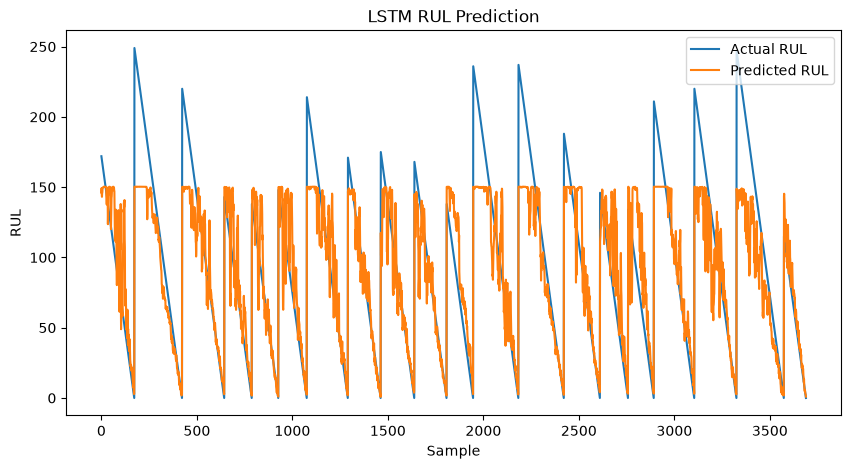

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(actual, label="Actual RUL")
plt.plot(predictions, label="Predicted RUL")

plt.xlabel("Sample")
plt.ylabel("RUL")
plt.title("LSTM RUL Prediction")

plt.legend()
plt.show()

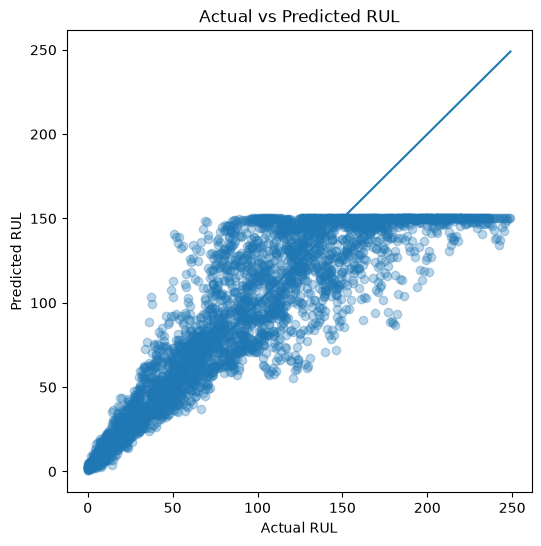

In [26]:
plt.figure(figsize=(6, 6))

plt.scatter(actual, predictions, alpha=0.3)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.plot(
    [actual.min(), actual.max()],
    [actual.min(), actual.max()]
)

plt.show()

In [27]:
print("Actual RUL statistics:")
print(pd.Series(actual).describe())

Actual RUL statistics:
count    3690.000000
mean       96.425201
std        60.782036
min         0.000000
25%        46.000000
50%        92.000000
75%       139.000000
max       249.000000
dtype: float64


LSTM Baseline Model

The baseline LSTM model uses a sequence window of 20 cycles.

Model configuration:
- Input size: 24
- Hidden size: 64
- Number of LSTM layers: 2
- Dropout: 0.2
- Window size: 20 cycles

Baseline validation performance:
- MAE: 21.17
- RMSE: 29.93

This model is used as the baseline for subsequent experiments. In the
following experiments, model hyperparameters will be modified individually
while keeping the remaining configuration fixed, allowing the effect of
each parameter to be evaluated against the baseline.

In [28]:
# Window Size Experiment Results

results = {
    "Window Size": [20, 30, 50, 75, 100, 140, 180],
    "MAE": [21, 20, 16, 13, 9, 7, 4.5],
    "Validation RUL Mean": [96.43, "-", 82.33, "-", 60.00, 44.97, 32.67],
    "Validation RUL Max": [249, "-", 219, "-", 169, 129, 89]
}

results_df = pd.DataFrame(results)

display(results_df)

# Question:
# Does increasing the window size actually improve the LSTM's ability
# to exploit longer temporal dependencies, or does the MAE decrease
# partly because larger windows exclude early-life samples with higher RUL?

,Window Size,MAE,Validation RUL Mean,Validation RUL Max
0,20,21.0,96.43,249
1,30,20.0,-,-
2,50,16.0,82.33,219
3,75,13.0,-,-
4,100,9.0,60.0,169
5,140,7.0,44.97,129
6,180,4.5,32.67,89


In [29]:
# Fair comparison: evaluate only on samples with RUL <= 80

mask = actual <= 80

actual_80 = actual[mask]
predictions_80 = predictions[mask]

mae_80 = mean_absolute_error(actual_80, predictions_80)
rmse_80 = np.sqrt(mean_squared_error(actual_80, predictions_80))

print("RUL range: 0-80")
print("Number of samples:", len(actual_80))
print(f"MAE  : {mae_80:.2f}")
print(f"RMSE : {rmse_80:.2f}")

RUL range: 0-80
Number of samples: 1620
MAE  : 10.71
RMSE : 16.86


In [30]:
# Window Size Experiment Results

results = {
    "Window Size": [20, 50, 100, 140, 180],
    "Overall MAE": [21.84, 16, 9, 7, 4.5],
    "MAE (RUL <= 80)": [11.54, 8.75, 6.04, 4.78, 3.33],
    "RMSE (RUL <= 80)": [19.55, 14.00, 8.58, 6.65, 4.32],
    "Validation Samples (RUL <= 80)": [1620, 1462, 1060, 625, 625]
}

results_df = pd.DataFrame(results)

display(results_df)

# Question:
# Does increasing the window size actually improve the LSTM's ability
# to exploit longer temporal dependencies, or does the MAE decrease
# partly because larger windows exclude early-life samples with higher RUL?

,Window Size,Overall MAE,MAE (RUL <= 80),RMSE (RUL <= 80),Validation Samples (RUL <= 80)
0,20,21.84,11.54,19.55,1620
1,50,16.00,8.75,14.00,1462
2,100,9.00,6.04,8.58,1060
3,140,7.00,4.78,6.65,625
4,180,4.50,3.33,4.32,625


### Hidden Size Tuning

The baseline model uses a hidden size of 64. To investigate whether increasing
the model capacity improves performance, hidden sizes of 128 and 256 were
also tested while keeping all other hyperparameters fixed.

| Hidden Size | MAE | RMSE |
|------------:|----:|-----:|
| 64 (Baseline) | 21.17 | 29.93 |
| 128 | 20.70 | 29.00 |
| 256 | 20.67 | 28.17 |

Increasing the hidden size resulted in only marginal improvements. The MAE
improved by only 0.50 from 64 to 256 despite substantially increasing the
model capacity and computational cost. Therefore, a hidden size of 64 is
retained as a simpler and more computationally efficient configuration.

### LSTM Layers and Dropout Tuning

The effect of the number of LSTM layers and dropout rate was evaluated while
keeping the input size, hidden size, window size, optimizer, and other
hyperparameters fixed.

| LSTM Layers | Dropout | MAE | RMSE |
|------------:|--------:|----:|-----:|
| 1 | N/A | 20.87 | 28.79 |
| 2 | 0.1 | 21.17 | 30.20 |
| 2 | 0.2 (Baseline) | 21.17 | 29.93 |
| 2 | 0.3 | 22.59 | 30.64 |

The single-layer LSTM achieved the lowest MAE and RMSE among the tested
configurations. Increasing the dropout rate for the two-layer LSTM did not
improve performance; in fact, a dropout rate of 0.3 resulted in a noticeable
increase in MAE. Therefore, the single-layer LSTM is currently preferred
due to its simpler architecture and better validation performance.

### Learning Rate Tuning

The learning rate was varied while keeping the window size, hidden size,
number of LSTM layers, and other hyperparameters fixed.

| Learning Rate | MAE | RMSE |
|--------------:|----:|-----:|
| 0.0005 | 21.96 | 30.90 |
| 0.001 | 20.87 | 28.79 |
| **0.002** | **19.70** | 27.52 |
| 0.003 | 19.75 | **27.33** |
| 0.004 | 21.03 | 29.49 |

Increasing the learning rate from 0.0005 to 0.002 substantially improved
validation performance. However, increasing it further to 0.004 resulted
in a deterioration in both MAE and RMSE, indicating that the learning rate
had become too large. A learning rate of 0.002 achieved the lowest MAE,
while 0.003 achieved the lowest RMSE.

For subsequent experiments, a learning rate of 0.002 is selected based on
MAE, which is the primary evaluation metric.

### Batch Size Tuning

The batch size was varied while keeping the other model and training
hyperparameters fixed.

| Batch Size | MAE | RMSE |
|-----------:|----:|-----:|
| **64 (Baseline)** | **19.70** | **27.52** |
| 32 | 20.47 | 29.38 |
| 128 | 20.54 | 29.00 |

A batch size of 64 achieved the best performance among the tested values.
Both decreasing the batch size to 32 and increasing it to 128 resulted in
worse MAE and RMSE. Therefore, a batch size of 64 is retained for the
subsequent experiments.

### Model Performance After Hyperparameter Tuning

The baseline LSTM model achieved an MAE of 21.17 and an RMSE of 29.93.
Hyperparameters were then tuned individually while keeping the remaining
configuration fixed.

The final selected configuration is:

- Window size: 20
- Input size: 24
- Hidden size: 64
- Number of LSTM layers: 1
- Learning rate: 0.002
- Batch size: 64
- Dropout: Not applicable (single LSTM layer)

The tuned model achieved:

- **MAE: 19.70**
- **RMSE: 27.52**

| Model | MAE | RMSE |
|---|---:|---:|
| Baseline LSTM | 21.17 | 29.93 |
| **After Hyperparameter Tuning** | **19.70** | **27.52** |

The tuned model improved the MAE by approximately **6.9%** and the RMSE by
approximately **8.1%** compared with the baseline model.

In [31]:
print("Training RUL:")
print(train_df["RUL"].describe())

print("\nValidation RUL:")
print(val_df["RUL"].describe())

print("Max training RUL:", train_df["RUL"].max())
print("Max validation RUL:", val_df["RUL"].max())

Training RUL:
count    16561.000000
mean       108.377815
std         69.639875
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        361.000000
Name: RUL, dtype: float64

Validation RUL:
count    4070.000000
mean      105.488698
std        65.659973
min         0.000000
25%        50.000000
50%       101.000000
75%       153.000000
max       268.000000
Name: RUL, dtype: float64
Max training RUL: 361
Max validation RUL: 268


In [32]:
print("Prediction statistics:")
print(pd.Series(predictions).describe())

print("\nMaximum prediction:", predictions.max())
print("Minimum prediction:", predictions.min())

print("\nNumber of predictions > 160:",
      np.sum(predictions > 160))

print("Number of predictions > 200:",
      np.sum(predictions > 200))

print("Training sequence RUL statistics:")
print(pd.Series(y_train).describe())

print("\nValidation sequence RUL statistics:")
print(pd.Series(y_val).describe())

Prediction statistics:
count    3690.000000
mean       91.797508
std        48.427311
min         0.792661
25%        49.196527
50%        94.868942
75%       142.479412
max       150.319916
dtype: float64

Maximum prediction: 150.31992
Minimum prediction: 0.7926614

Number of predictions > 160: 0
Number of predictions > 200: 0
Training sequence RUL statistics:
count    15041.000000
mean        99.420647
std         65.098724
min          0.000000
25%         47.000000
50%         94.000000
75%        143.000000
max        342.000000
dtype: float64

Validation sequence RUL statistics:
count    3690.000000
mean       96.425201
std        60.782036
min         0.000000
25%        46.000000
50%        92.000000
75%       139.000000
max       249.000000
dtype: float64


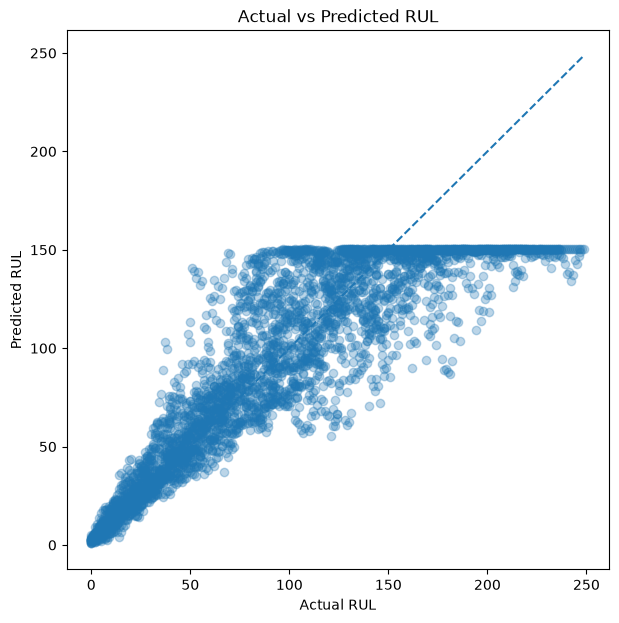

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
plt.scatter(y_val, predictions, alpha=0.3)

plt.plot(
    [0, max(y_val)],
    [0, max(y_val)],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")
plt.show()

In [34]:
high = y_val > 160

print("Actual high-RUL samples:", high.sum())
print("Mean actual:", y_val[high].mean())
print("Mean predicted:", predictions[high].mean())
print("Max predicted:", predictions[high].max())
print("MAE for RUL > 160:",
      np.mean(np.abs(y_val[high] - predictions[high])))

Actual high-RUL samples: tensor(628)
Mean actual: tensor(193.3424)
Mean predicted: 144.98468
Max predicted: 150.31992


TypeError: mean() got an unexpected keyword argument 'axis'